In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-07-16 13:19:58.355925: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-07-16 13:19:58.417372: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-16 13:19:58.417413: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-16 13:19:58.418907: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-07-16 13:19:58.426973: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-07-16 13:19:58.427749: I tensorflow/core/platform/cpu_feature_guard.cc:1

## Params

In [3]:
V_width = 1
# V_E_buffer_array = np.linspace(30,90,30).astype(int)
# V_E_buffer_array = np.linspace(90,150,30).astype(int)
V_E_buffer_array = np.arange(23).astype(int)[::2]
# V_E_buffer_array = [29]
E_width = 1

N_training_repeats = 20
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 16}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

# shuffle time bins in a way that is the same across movie repeats
shuffle_time = False

# shuffle trial index for each timestep
shuffle_trial_per_time = True

# Put variable names here for parameters we want saved.
save_vars = {
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "opt_params",
    "V_width",
    "V_E_buffer_array",
    "E_width",
    "train_fraction",
    "samp_keep",
    "shuffle_time"
}


In [4]:
V_E_buffer_array

array([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18, 20, 22])

## Prepare data

In [5]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
mov_ind = D.mov_ind
mov_name = D.movname
save_vars.add('mov_ind')

# data_path = os.path.join(project_folder, 'data', 'bar_stim_data')
# D = ds.DataBar(data_path)
# mov_name = 'bar'

save_vars.add('mov_name')
print(f'current stimulus is {mov_name}')

current stimulus is opticflow


## Run analysis

In [6]:
experiment_dims = (len(V_E_buffer_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)
save_vars.update(
    {
        "mi_averages_train",
        "mi_averages_test",
        "mi_stdevs_train",
        "mi_stdevs_test",
        "train_points",
        "test_points",
    }
)

for i, V_E_buffer in tqdm(enumerate(V_E_buffer_array)):
    for training_repeat in range(N_training_repeats):
        
        trial_inds = (i, training_repeat)

        # Domains, training and test subsets
        D.reset()
        D.trim(20)
        if shuffle_time:
            D.shuffle_time_and_trial()
        
        if shuffle_trial_per_time:
            D.shuffle_trial_per_time()


        V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
        (
            current_train_points,
            current_test_points,
        ) = tools.generate_train_test_indices(V.P, train_fraction)
        train_points[trial_inds] = current_train_points
        test_points[trial_inds] = current_test_points

        # solve IB for training set points
        coarse_grainer = mds.PolynomialLayer(output_dim=V.N, order=1)
        critic_function = mds.SeparableCritic(**critic_params)

        # Train current
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )
        
        # Measure mutual information
        # Measure InfoNCE for train
        T = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[trial_inds] = mi_train["mi"]
        mi_stdevs_train[trial_inds] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T = T = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[trial_inds] = mi_test["mi"]
        mi_stdevs_test[trial_inds] = mi_test["mi_stdev"]

0it [00:00, ?it/s]

2024-07-16 13:20:11.026627: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-07-16 13:20:11.027327: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


11it [1:48:11, 611.34s/it]2024-07-16 16:13:48.921346: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:422] ShuffleDatasetV3:3487: Filling up shuffle buffer (this may take a while): 55311 of 98600
2024-07-16 16:13:49.305397: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] Shuffle buffer filled.
12it [2:58:42, 893.56s/it] 


## Save

In [7]:
# select variables
coarse_grainer_type = type(coarse_grainer)
critic_type = type(critic_function)
save_vars.update({"critic_type", "coarse_grainer_type"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [8]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
if shuffle_time:
    prepend = "(shuffled) "
elif shuffle_trial_per_time:
    prepend = "(shuffled trial per time) "
else:
    prepend = ""

stim = mov_name
full_file_path = os.path.join(save_directory, stim, prepend + f'{V_E_buffer_array[0]} - {V_E_buffer_array[-1]}.dat')
# full_file_path = os.path.join(save_directory, stim, prepend + 'huge intervals.dat')
# full_file_path = os.path.join(save_directory, stim, prepend + '90 to 150.dat')
# full_file_path = os.path.join(save_directory, stim, prepend + 'all neurons.dat')
print(f"data will be saved to:\n{full_file_path}")

data will be saved to:
/home/adam/Documents/projects/retina-past-future-ib/analyses/noise correlations/saved/opticflow/(shuffled trial per time) 0 - 22.dat


In [9]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [3]:
# stim = 'bar'
stim = 'opticflow'
# stim = 'bushes'

### Large prediction interval behavior

In [4]:
load_path = project_folder + 'analyses/noise correlations/saved/opticflow/0 - 22.dat'
load_path_sh = project_folder + 'analyses/noise correlations/saved/opticflow/(shuffled trial per time) 0 - 22.dat'

with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

with open(load_path_sh, 'rb') as f:
    data_dict_sh = pickle.load(f)
data_sh = Namespace(**data_dict_sh)

In [5]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, stdevs

In [6]:
mi_averages, mi_stdevs = process_trials(data.mi_averages_test, data.mi_stdevs_test)
mi_averages_sh, mi_stdevs_sh = process_trials(data_sh.mi_averages_test, data_sh.mi_stdevs_test)

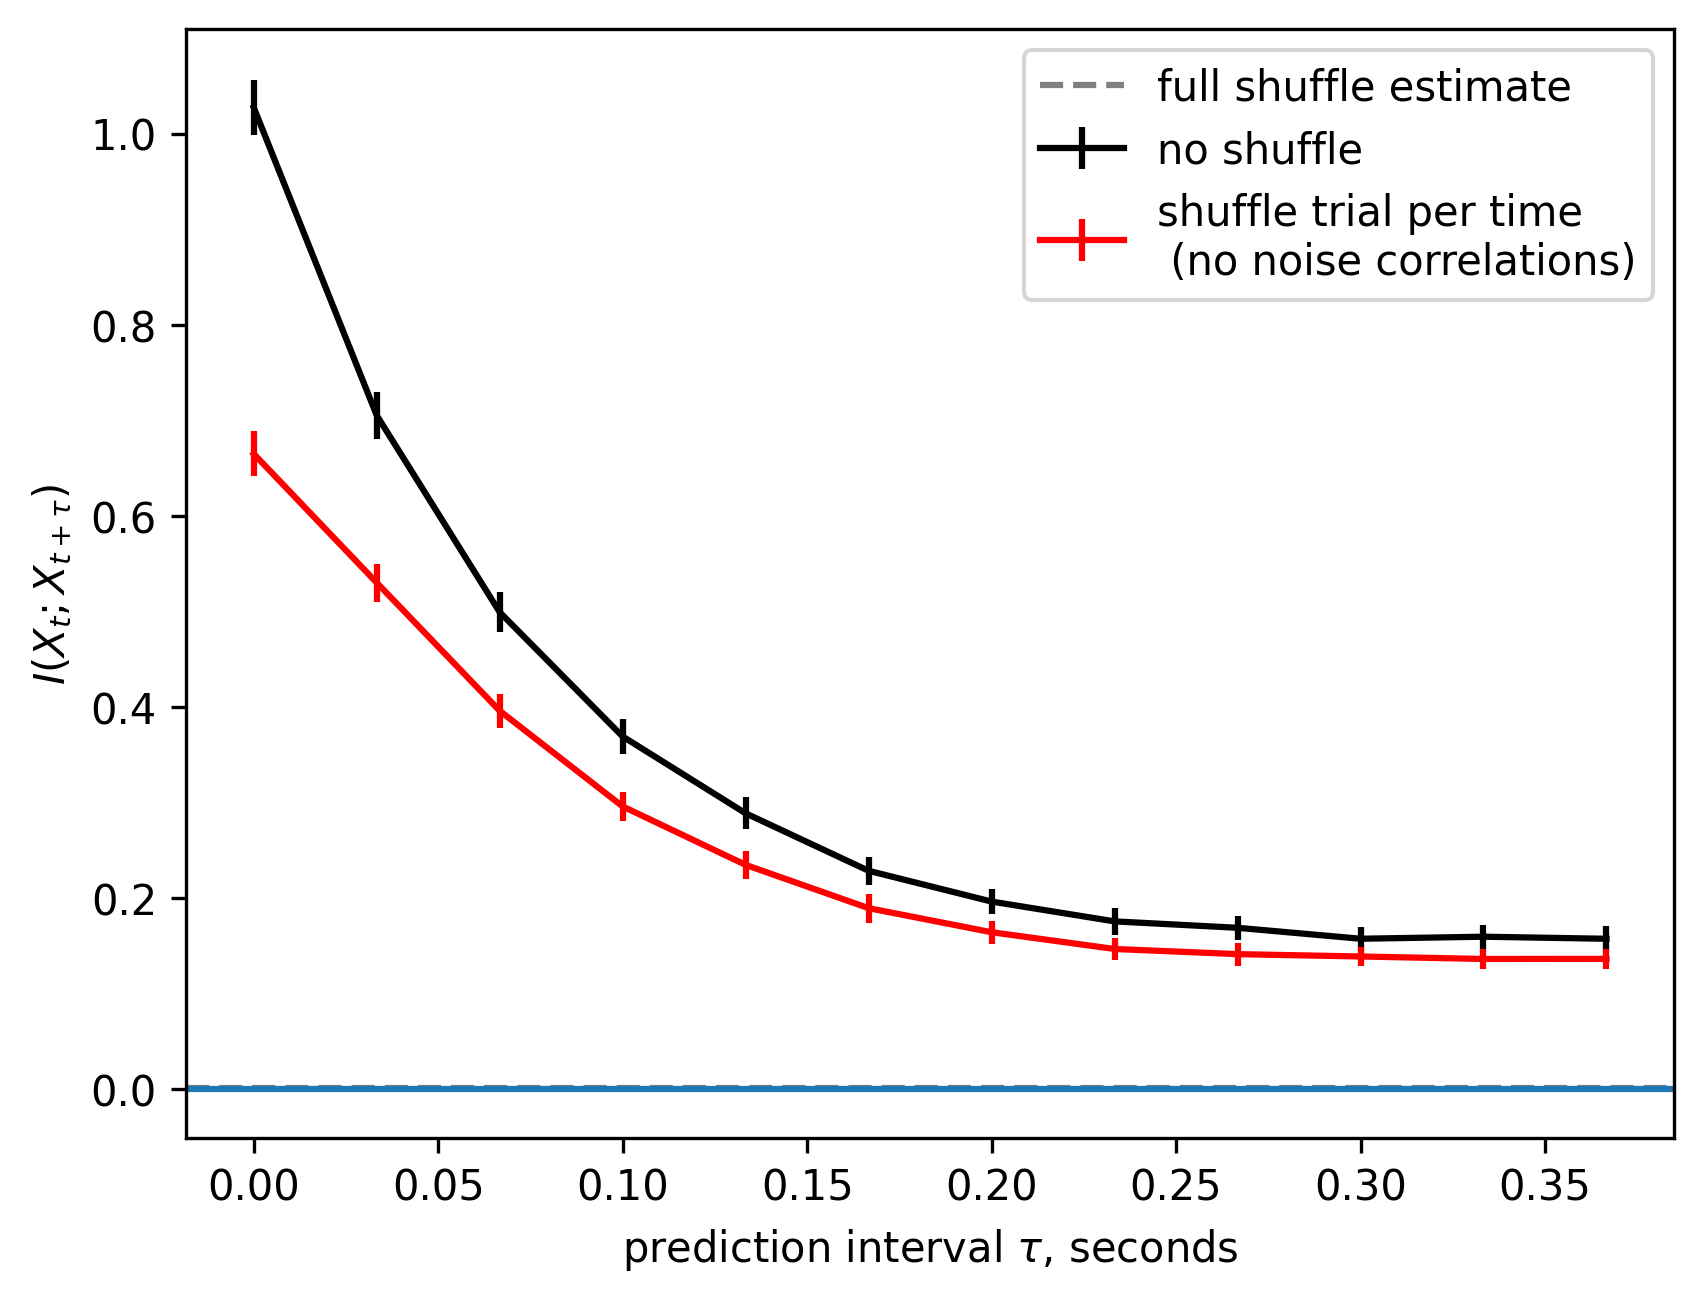

In [8]:
fig, ax = plt.subplots(dpi=300)
# plt.semilogy()
ax.errorbar(data.V_E_buffer_array / 60, mi_averages / np.log(2), mi_stdevs / np.log(2), color='k', label="no shuffle")
ax.errorbar(data.V_E_buffer_array / 60, mi_averages_sh / np.log(2), mi_stdevs_sh / np.log(2), color='r', label="shuffle trial per time \n (no noise correlations)")
ax.set_xlabel(r'prediction interval $\tau$, seconds')
ax.set_ylabel(r'$I(X_t; X_{t+\tau})$')
ax.axhline(0.001 / np.log(2), linestyle='--', color='grey', label='full shuffle estimate')
ax.axhline(0)
ax.legend()

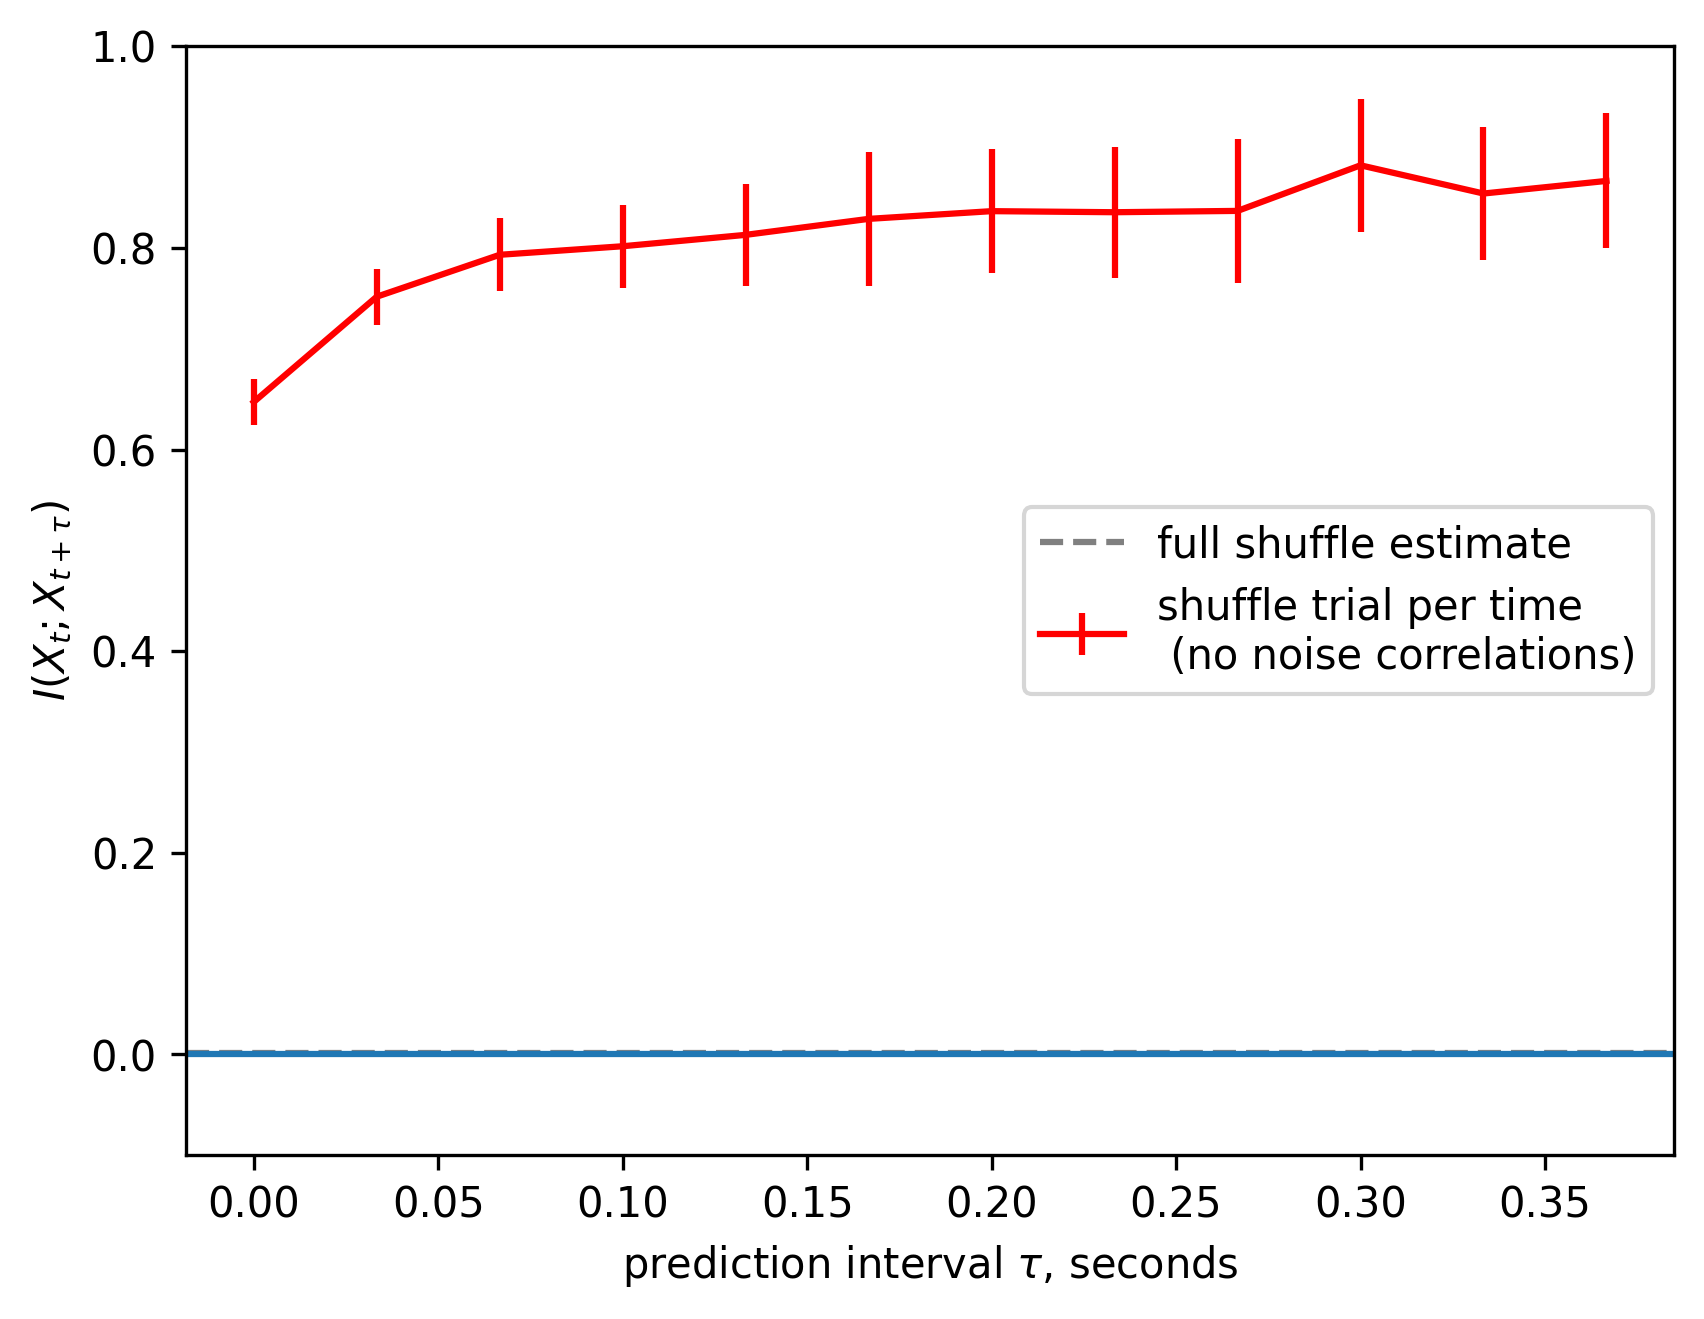

In [11]:
fig, ax = plt.subplots(dpi=300)
# plt.semilogy()
# ax.errorbar(data.V_E_buffer_array / 60, mi_averages / np.log(2), mi_stdevs / np.log(2), color='k', label="no shuffle")
ax.errorbar(data.V_E_buffer_array / 60, mi_averages_sh / mi_averages, mi_stdevs_sh / mi_averages, color='r', label="shuffle trial per time \n (no noise correlations)")
ax.set_xlabel(r'prediction interval $\tau$, seconds')
ax.set_ylabel(r'$I(X_t; X_{t+\tau})$')
ax.set_ylim(-0.1,1)
ax.axhline(0.001 / np.log(2), linestyle='--', color='grey', label='full shuffle estimate')
ax.axhline(0)
ax.legend()